# Imports

In [60]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp

# Global parameters
A = np.array([[1.0, 1.0],
              [4.0, -2.0]])   # sedlo iz pripravljalne naloge
x0_pos = [2.0, -3.0]          # posebna zacetna tocka
meja = 3.0                    # obmocje [-meja, meja]^2
t_max = 10.0

rtol, atol = 1e-10, 1e-12

# Funkcije

In [61]:
# Simbolno: sled, determinanta, lastni pari in analiticna resitev x(t) = exp(A t) x0
t = sp.symbols("t", real=True)
A_sym = sp.Matrix([[1, 1], [4, -2]])
tau_sym = A_sym.trace()
Delta_sym = A_sym.det()
eig_sym = A_sym.eigenvects()  # [(lambda, krat., [v]), ...]

x_an = sp.simplify((A_sym * t).exp() * sp.Matrix(x0_pos).applyfunc(sp.nsimplify))
x_an_np = sp.lambdify(t, x_an, "numpy")

In [71]:
def rhs_lin(t, y, A):
    return A @ y

def izven(t, y, *args):
    # ustavi integracijo, ko trajektorija zapusti obmocje
    return meja + 0.5 - np.max(np.abs(y))
izven.terminal = True

def trajektorija(rhs, y0, t_max, args=()):
    # naprej in nazaj v casu
    deli = []
    for smer in (1, -1):
        sol = solve_ivp(rhs, (0, smer * t_max), y0, args=args, events=izven,
                        rtol=rtol, atol=atol, max_step=0.02)
        deli.append(sol.y)
    return np.hstack([deli[1][:, ::-1], deli[0]])

def klasifikacija(A, eps=1e-12):
    tau, Delta = np.trace(A), np.linalg.det(A)
    D = tau**2 - 4 * Delta
    if Delta < -eps:
        return "sedlo"
    if abs(Delta) < eps:
        return "degenerirano (Delta = 0)"
    if abs(tau) < eps:
        return "center"
    if D > eps:
        return "stabilen vozel" if tau < 0 else "nestabilen vozel"
    if D < -eps:
        return "stabilno gorišče" if tau < 0 else "nestabilno gorišče"
    return "degeneriran vozel"

def fazni_portret(ax, A, zacetne, naslov=""):
    xs = np.linspace(-meja, meja, 40)
    X, Y = np.meshgrid(xs, xs)
    U = A[0, 0] * X + A[0, 1] * Y
    V = A[1, 0] * X + A[1, 1] * Y
    ax.streamplot(X, Y, U, V, color="lightgray", density=1.2, linewidth=0.8)

    # invariantni premici (samo za realne lastne vrednosti)
    lam, vec = np.linalg.eig(A)
    if np.all(np.isreal(lam)):
        s = np.linspace(-2 * meja, 2 * meja, 2)
        for l, v, c in zip(lam.real, vec.real.T, ["C3", "C0"]):
            ax.plot(s * v[0], s * v[1], "--", color=c, linewidth=1.5, label=rf"$\lambda = {l:+.2f}$")

    for y0 in zacetne:
        tr = trajektorija(rhs_lin, y0, t_max, args=(A,))
        ax.plot(tr[0], tr[1], color="black", linewidth=1)
        ax.plot(*y0, "o", color="black", markersize=3)

    ax.plot(0, 0, "o", color="red", markersize=5)
    ax.set_xlim(-meja, meja)
    ax.set_ylim(-meja, meja)
    ax.set_aspect("equal")
    ax.set_xlabel("$x$", fontsize=14)
    ax.set_ylabel("$y$", fontsize=14)
    ax.set_title(naslov)
    if np.all(np.isreal(lam)):
        ax.legend(loc="upper left")

# Testno območje

# Pripravljalna naloga (analitični del)

## Obravnavamo linearni 2D sistem iz učbenika:
$$ \dot{x} =x+y,$$
$$ \dot{y} =4x−2y.$$

In [63]:
t = sp.symbols('t')


x = sp.Function('x')(t)
y = sp.Function('y')(t)

xdot = sp.Eq(x.diff(t),x+y)
ydot = sp.Eq(y.diff(t),4*x-2*y)

display(xdot)
display(ydot)

Eq(Derivative(x(t), t), x(t) + y(t))

Eq(Derivative(y(t), t), 4*x(t) - 2*y(t))

## Zapišite Jacobijevo matriko sistema in izračunajte sled $\tau$ in determinanto $\Delta$.

In [64]:
Axx = sp.diff(xdot.rhs,x)
Axy = sp.diff(xdot.rhs,y)
Ayx = sp.diff(ydot.rhs,x)
Ayy = sp.diff(ydot.rhs,y)

A = sp.Matrix([[Axx,Axy],[Ayx,Ayy]])
display(A)


Trace = A.trace()
print(Trace)
Det = A.det()
print(Det)

Matrix([
[1,  1],
[4, -2]])

-1
-6


## Poišči lastni vrednosti matrike A

$$
\text{det}(A - \lambda I) = 0
$$

In [65]:
eigen = A.eigenvals()
print(eigen)

{2: 1, -3: 1}


## Izračunaj lastna vektorja matrike A
$$
A \mathbf{v} = \lambda \mathbf{v}
$$

In [66]:
#Eigen vector
eigenvectors = A.eigenvects()
for eigenvector in eigenvectors:
    lam, mult, vecs = eigenvector
    print(f"Eigenvalue: {lam}")
    print(f"Multiplicity: {mult}")
    print(f"Eigenvectors: {vecs[0]}")
    print()

Eigenvalue: -3
Multiplicity: 1
Eigenvectors: Matrix([[-1/4], [1]])

Eigenvalue: 2
Multiplicity: 1
Eigenvectors: Matrix([[1], [1]])



## Določite tip ravnotežja v izhodišču (0,0)

In [67]:
print("Tip ravnotezja:", klasifikacija(A))

Matrix([[1, 1], [4, -2]])


UFuncTypeError: Cannot cast ufunc 'det' input from dtype('O') to dtype('float64') with casting rule 'same_kind'

## Zapišite analitično rešitev (x(t),y(t)) za začetni pogoj (x(0),y(0)) = (2,−3)

Splošna rešitev homogene linearne diferencialne enačbe je linearna kombinacija lastnih načinov:
$$\mathbf{x}(t) = c_1 e^{\lambda_1 t} \mathbf{v}_1 + c_2 e^{\lambda_2 t} \mathbf{v}_2$$
$$\begin{bmatrix} x(t) \\ y(t) \end{bmatrix} = c_1 e^{2t} \begin{bmatrix} 1 \\ 1 \end{bmatrix} + c_2 e^{-3t} \begin{bmatrix} 1 \\ -4 \end{bmatrix}$$

Določitev konstant $c_1$ in $c_2$ iz začetnega pogoja pri $t = 0$
Dobimo sistem dveh linearnih enačb:
$c_1 + c_2 = 2 \implies c_2 = 2 - c_1$
$c_1 - 4c_2 = -3$

Vstavimo $c_2$ v drugo enačbo:
$$c_1 - 4(2 - c_1) = -3$$
$$5c_1 - 8 = -3 \implies 5c_1 = 5 \implies \mathbf{c_1 = 1}$$
$$c_2 = 2 - 1 \implies \mathbf{c_2 = 1}$$

Končna analitična rešitev
$$\begin{aligned} x(t) &= e^{2t} + e^{-3t} \\ y(t) &= e^{2t} - 4e^{-3t} \end{aligned}$$

# Naloga 1

S knjižnico NumPy (uporabite funkcijo numpy.linalg.eig) izračunajte lastne vrednosti in norma
lizirane lastne vektorje za matriko A. Preverite ujemanje z analitičnimi rezultati iz pripravljalnega
dela.

In [ ]:
print(A)
eig_val = np.linalg.eigvals([[1,1],[4,-2]])
eig_vec = np.linalg.eig([[1,1],[4,-2]])
print(eig_val)
print(eig_vec[1][0])
print(eig_vec[1][1])

Matrix([[1, 1], [4, -2]])
[ 2.+0.j -3.+0.j]
[ 0.70710678+0.j -0.24253563+0.j]
[0.70710678+0.j 0.9701425 +0.j]


In [ ]:
x0 = np.array([2.0, -3.0])

sol = solve_ivp(rhs_lin, (0.0, 1.0), x0, args=(A,), rtol=1e-10, atol=1e-12)
x_num = sol.y[:, -1]
x_num

array([7.43884317, 7.18990783])

Preverite ujemanje z analitičnimi rezultati iz pripravljalnega dela.

In [70]:
# x0 mora biti stolpični vektor oblike (2, 1) ali seznam dveh števil
x0 = sp.Matrix([2, -3])
t = sp.symbols('t')
A_sym = sp.Matrix([[1,1],[4,-2]])
# Pravilno množenje matrike s skalarjem: A_sym * t
x_an = sp.simplify((A_sym * t).exp() * x0)
x_an_np = sp.lambdify(t, x_an, "numpy")


display(x_an)
print(x_an_np(1.0).ravel())

Matrix([
[(exp(5*t) + 1)*exp(-3*t)],
[(exp(5*t) - 4)*exp(-3*t)]])

[7.43884317 7.18990783]


In [69]:
x = lambda y: 1+y
x(2)

3

# Naloga 2: Izris vektorskega polja in invariantnih premic sedla

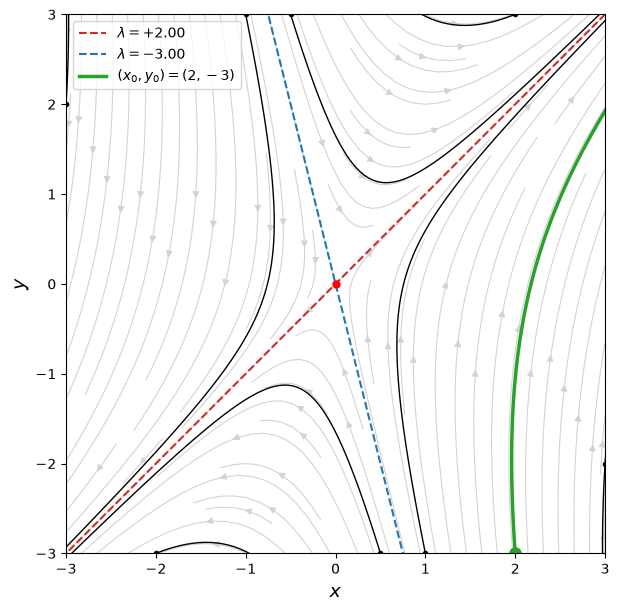

In [73]:
zacetne = [(0.5, -3), (1, -3), (-0.5, 3), (-1, 3), (-3, 2), (3, -2), (-2, -3), (2, 3)]
A = np.array([[1,1],[4,-2]])
fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111)
fazni_portret(ax, A, zacetne)

# posebna trajektorija (2, -3)
tr = trajektorija(rhs_lin, x0_pos, t_max, args=(A,))
ax.plot(tr[0], tr[1], color="C2", linewidth=2.5, label=r"$(x_0, y_0) = (2, -3)$")
ax.plot(*x0_pos, "o", color="C2", markersize=8)
ax.legend(loc="upper left")
plt.show()

# Naloga 3: Eksploracija topologij fazne ravnine

In [ ]:
def matrix_check_2D(a,b,c,d):
    Tr = a + d
    Det = a*d - b*c
    print("Trace:", Tr, "Determinant:", Det)
    Atemp = np.matrix([[a, b], [c, d]])
    eigenvalues = np.linalg.eigvals(Atemp)
    lam1_re = eigenvalues[0].real
    lam1_im = eigenvalues[0].imag
    lam2_re = eigenvalues[1].real
    lam2_im = eigenvalues[1].imag
    print(f"   - Lambda 1: {lam1_re:+.3f} {lam1_im:+.3f} i")
    print(f"   - Lambda 2: {lam2_re:+.3f} {lam2_im:+.3f} i")
    tip = klasifikacija(Atemp)
    print("Type:", tip)
    print("--------------------------\n")
    return Tr, Det

matrix_check_2D( 1, 1, 4,-2)
matrix_check_2D(-3, 1, 1,-3)
matrix_check_2D(-1, 2,-2,-1)
matrix_check_2D(0.0,1.0,-4.0, 0.0)

Trace: -1 Determinant: -6
   - Lambda 1: +2.000 +0.000 i
   - Lambda 2: -3.000 +0.000 i
Type: sedlo
--------------------------

Trace: -6 Determinant: 8
   - Lambda 1: -2.000 +0.000 i
   - Lambda 2: -4.000 +0.000 i
Type: stabilen vozel
--------------------------

Trace: -2 Determinant: 5
   - Lambda 1: -1.000 +2.000 i
   - Lambda 2: -1.000 -2.000 i
Type: stabilno gorišče
--------------------------

Trace: 0.0 Determinant: 4.0
   - Lambda 1: +0.000 +2.000 i
   - Lambda 2: +0.000 -2.000 i
Type: center
--------------------------



(0.0, 4.0)

| Tip | Matrika | Sled | Determinatn| Komentar |
|-----|---------|------|------------|---------|
| Sedlo | $$\begin{pmatrix}1 & 1 \\ 4 & -2\end{pmatrix}$$ | -1 | -6 | Ima invariantne premice |

In [81]:
matrike = {
    # 1. NA KRIVULJI (D = 0)
    "Na krivulji (tau < 0)": np.array([[-2.0, 1.0], [0.0, -2.0]]),    # tau = -4, Delta = 4, D = 0
    "Na krivulji (tau = 0)": np.array([[0.0, 1.0], [0.0, 0.0]]),      # tau = 0, Delta = 0, D = 0
    "Na krivulji (tau > 0)": np.array([[2.0, 1.0], [0.0, 2.0]]),      # tau = 4, Delta = 4, D = 0
    # 2. NAD KRIVULJO (D < 0)
    "Nad krivuljo (tau < 0)": np.array([[-1.0, 2.0], [-2.0, -1.0]]),  # tau = -2, Delta = 5, D = -16
    "Nad krivuljo (tau = 0)": np.array([[0.0, 2.0], [-2.0, 0.0]]),    # tau = 0, Delta = 4, D = -16
    "Nad krivuljo (tau > 0)": np.array([[1.0, 2.0], [-2.0, 1.0]]),    # tau = 2, Delta = 5, D = -16

    # 3. POD KRIVULJO (D > 0)
    "Pod krivuljo (tau < 0)": np.array([[-3.0, 0.0], [0.0, -1.0]]),   # tau = -4, Delta = 3, D = 4
    "Pod krivuljo (tau = 0)": np.array([[0.0, 2.0], [2.0, 0.0]]),     # tau = 0, Delta = -4, D = 16
    "Pod krivuljo (tau > 0)": np.array([[3.0, 0.0], [0.0, 1.0]]),     # tau = 4, Delta = 3, D = 4
}

print(f"{'tip':18s} {'A':>28s} {'tau':>5s} {'Delta':>6s} {'D':>6s}   lambda")
for ime, M in matrike.items():
    tau, Delta = np.trace(M), np.linalg.det(M)
    lam = np.linalg.eigvals(M)
    print(f"{ime:18s} {str(M.tolist()):>28s} {tau:5.1f} {Delta:6.1f} {tau**2 - 4 * Delta:6.1f}   "
          f"{np.round(lam, 3)}  -> {klasifikacija(M)}")

tip                                           A   tau  Delta      D   lambda
Na krivulji (tau < 0)   [[-2.0, 1.0], [0.0, -2.0]]  -4.0    4.0    0.0   [-2.+0.j -2.+0.j]  -> degeneriran vozel
Na krivulji (tau = 0)     [[0.0, 1.0], [0.0, 0.0]]   0.0    0.0    0.0   [0.+0.j 0.+0.j]  -> degenerirano (Delta = 0)
Na krivulji (tau > 0)     [[2.0, 1.0], [0.0, 2.0]]   4.0    4.0    0.0   [2.+0.j 2.+0.j]  -> degeneriran vozel
Nad krivuljo (tau < 0)  [[-1.0, 2.0], [-2.0, -1.0]]  -2.0    5.0  -16.0   [-1.+2.j -1.-2.j]  -> stabilno gorišče
Nad krivuljo (tau = 0)    [[0.0, 2.0], [-2.0, 0.0]]   0.0    4.0  -16.0   [0.+2.j 0.-2.j]  -> center
Nad krivuljo (tau > 0)    [[1.0, 2.0], [-2.0, 1.0]]   2.0    5.0  -16.0   [1.+2.j 1.-2.j]  -> nestabilno gorišče
Pod krivuljo (tau < 0)   [[-3.0, 0.0], [0.0, -1.0]]  -4.0    3.0    4.0   [-3.+0.j -1.+0.j]  -> stabilen vozel
Pod krivuljo (tau = 0)     [[0.0, 2.0], [2.0, 0.0]]   0.0   -4.0   16.0   [ 2.+0.j -2.+0.j]  -> sedlo
Pod krivuljo (tau > 0)     [[3.0, 0.0], [

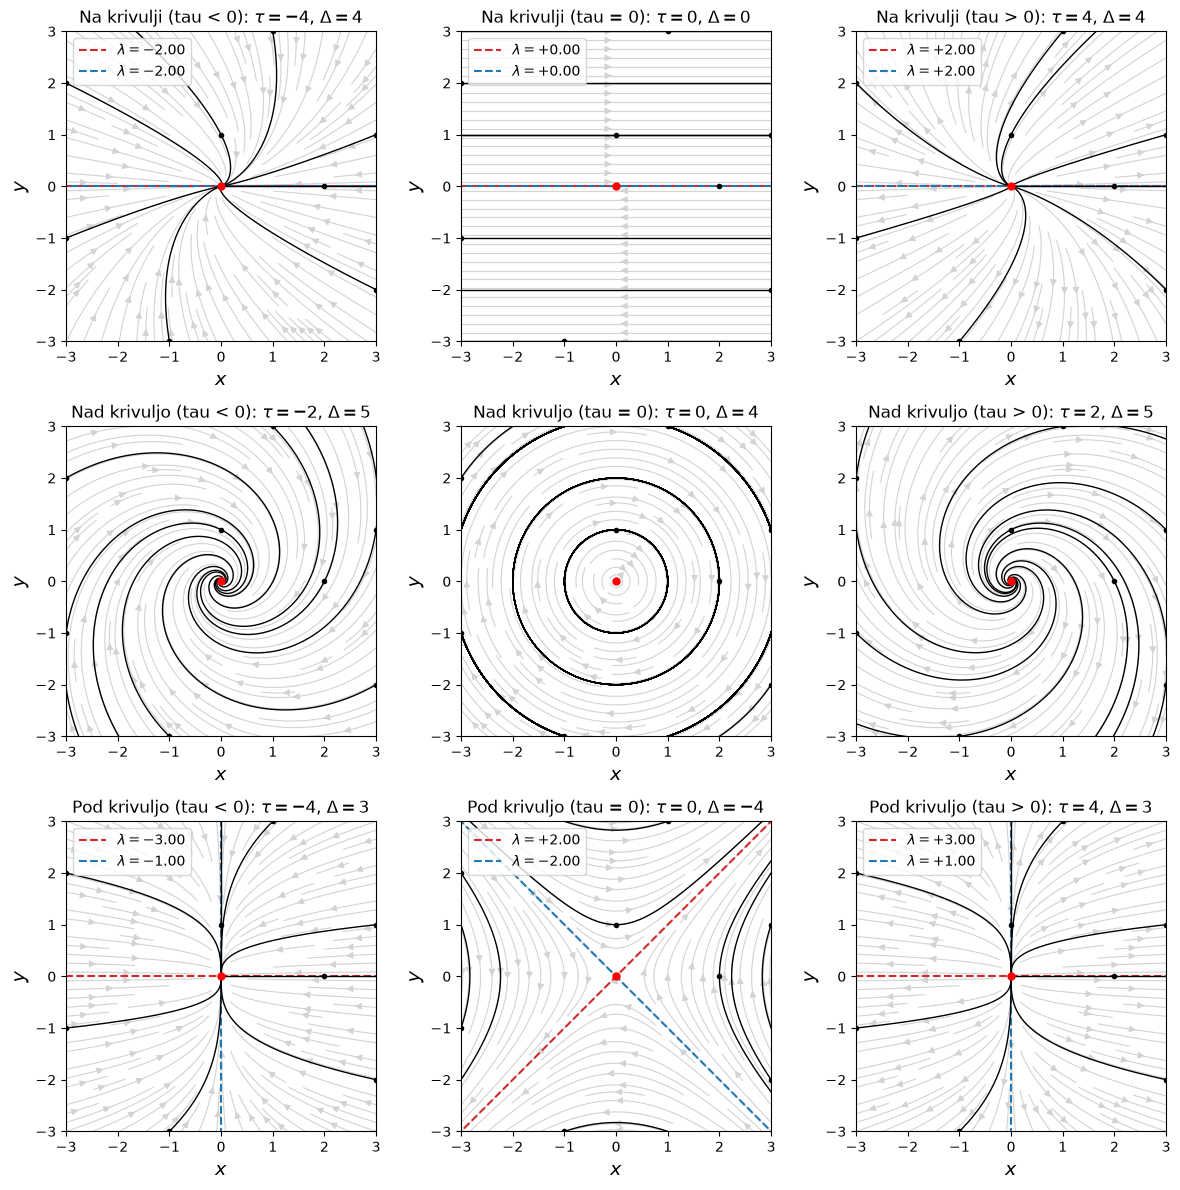

In [ ]:
zacetne_3 = [(3, 1), (-3, -1), (1, 3), (-1, -3), (3, -2), (-3, 2), (2, 0), (0, 1)]

fig = plt.figure(figsize=(12, 12))
for i, (ime, M) in enumerate(matrike.items()):
    ax = fig.add_subplot(3, 3, i + 1)
    fazni_portret(ax, M, zacetne_3, rf"{ime}: $\tau = {np.trace(M):.0f}$, $\Delta = {np.linalg.det(M):.0f}$")
plt.tight_layout()
plt.show()

Trace: -4.0 Determinant: 4.0
   - Lambda 1: -2.000 +0.000 i
   - Lambda 2: -2.000 +0.000 i
Type: degeneriran vozel
--------------------------

Trace: 0.0 Determinant: 0.0
   - Lambda 1: +0.000 +0.000 i
   - Lambda 2: +0.000 +0.000 i
Type: degenerirano (Delta = 0)
--------------------------

Trace: 4.0 Determinant: 4.0
   - Lambda 1: +2.000 +0.000 i
   - Lambda 2: +2.000 +0.000 i
Type: degeneriran vozel
--------------------------

Trace: -2.0 Determinant: 5.0
   - Lambda 1: -1.000 +2.000 i
   - Lambda 2: -1.000 -2.000 i
Type: stabilno gorišče
--------------------------

Trace: 0.0 Determinant: 4.0
   - Lambda 1: +0.000 +2.000 i
   - Lambda 2: +0.000 -2.000 i
Type: center
--------------------------

Trace: 2.0 Determinant: 5.0
   - Lambda 1: +1.000 +2.000 i
   - Lambda 2: +1.000 -2.000 i
Type: nestabilno gorišče
--------------------------

Trace: -4.0 Determinant: 3.0
   - Lambda 1: -3.000 +0.000 i
   - Lambda 2: -1.000 +0.000 i
Type: stabilen vozel
--------------------------

Trace: 0.0

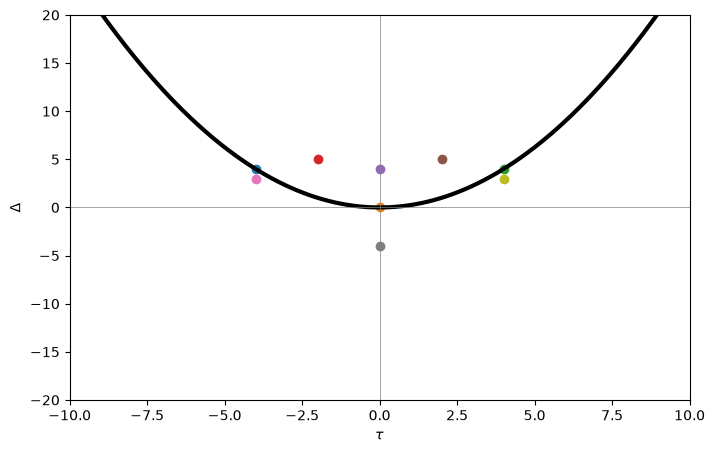

In [84]:
tau_os = np.linspace(-10,10,200)
delta_os = tau_os**2/4.0

fig = plt.figure(figsize = (8,5))
ax = fig.add_subplot(111)

ax.plot(tau_os,delta_os, color = 'black', lw = 3)
ax.set_xlabel(r'$\tau$')
ax.set_ylabel(r'$\Delta$')
ax.set_xlim([-10,10])
ax.set_ylim([-20,20])

ax.axvline(0, color = 'gray', lw = 0.5, ls = '-')
ax.axhline(0, color = 'gray', lw = 0.5, ls = '-')


for key in matrike:
    M = matrike[key]
    tau, det = matrix_check_2D(M[0,0], M[0,1], M[1,0], M[1,1])
    ax.scatter(tau, det)

plt.show()

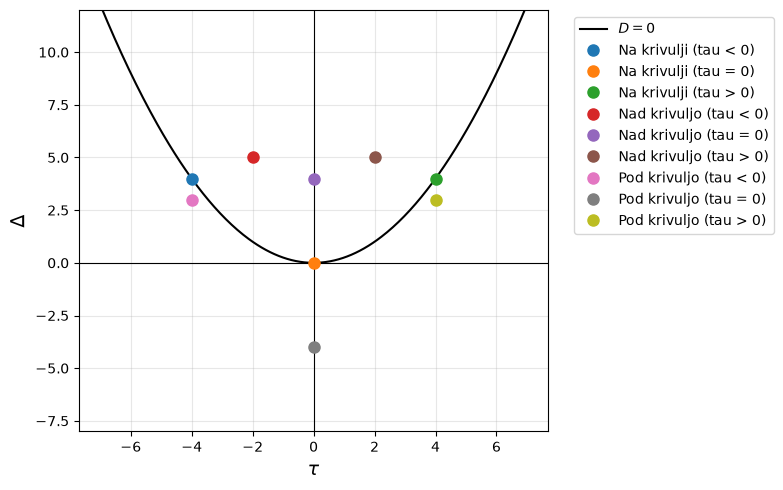

In [85]:
import numpy as np
import matplotlib.pyplot as plt

# Ravnina (tau, Delta)
tau_os = np.linspace(-7, 7, 300)

fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111)

ax.plot(tau_os, tau_os**2 / 4, color="black", label=r"$D = 0$")
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)

for ime, M in matrike.items():
    ax.plot(np.trace(M), np.linalg.det(M), "o", markersize=8, label=ime)

ax.set_xlabel(r"$\tau$", fontsize=14)
ax.set_ylabel(r"$\Delta$", fontsize=14)
ax.set_ylim(-8, 12)

# Postavitev legende desno zunaj grafa
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", frameon=True)

ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Razmislek 1

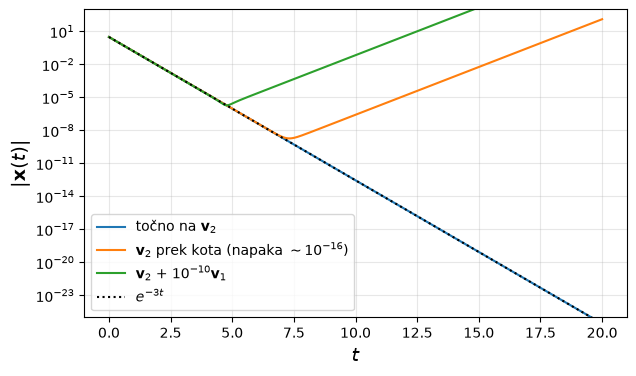

In [ ]:
# Zacetek na stabilni smeri v2 = (1, -4):
#  - (0.75, -3) je v plavajoci vejici tocno na v2
#  - smer prek kota ima zaokrozitveno napako ~1e-16
#  - motnja 1e-10 vzdolz v1
v1, v2 = np.array([1.0, 1.0]), np.array([1.0, -4.0])
y_stab = 0.75 * v2
phi = np.arctan2(-4.0, 1.0)
y_kot = np.linalg.norm(y_stab) * np.array([np.cos(phi), np.sin(phi)])
t_r = np.linspace(0, 20, 2000)

fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
for y0, oznaka in [(y_stab, r"točno na $\mathbf{v}_2$"),
                   (y_kot, r"$\mathbf{v}_2$ prek kota (napaka $\sim 10^{-16}$)"),
                   (y_stab + 1e-10 * v1, r"$\mathbf{v}_2$ + $10^{-10}\mathbf{v}_1$")]:
    sol = solve_ivp(rhs_lin, (0, 20), y0, args=(A,), t_eval=t_r, rtol=rtol, atol=1e-30)
    ax.plot(sol.t, np.linalg.norm(sol.y, axis=0), label=oznaka)
ax.plot(t_r, np.linalg.norm(y_stab) * np.exp(-3 * t_r), ":", color="black", label=r"$e^{-3t}$")
ax.set_yscale("log")
ax.set_ylim(1e-25, 1e3)
ax.set_xlabel("$t$", fontsize=14)
ax.set_ylabel(r"$|\mathbf{x}(t)|$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3, which="both")
plt.show()

# Razmislek 2

In [ ]:
# div f = Tr(J) za splosen linearen sistem
a, b, c, d, xs, ys = sp.symbols("a b c d x y")
f_lin = sp.Matrix([a * xs + b * ys, c * xs + d * ys])
print("div f =", sp.diff(f_lin[0], xs) + sp.diff(f_lin[1], ys))

# Hamiltonski oscilator: q' = dH/dp, p' = -dH/dq
q, p, m, k = sp.symbols("q p m k", positive=True)
H = p**2 / (2 * m) + k * q**2 / 2
f_ham = sp.Matrix([sp.diff(H, p), -sp.diff(H, q)])
J_ham = f_ham.jacobian([q, p])
display(J_ham)
print(f"tau = {J_ham.trace()},  Delta = {J_ham.det()}  -> center")

# Ploscina se skalira z det(exp(A t)) = exp(tau t)
print("det(exp(A t)) =", sp.simplify((A_sym * t).exp().det()))

div f = a + d


Matrix([
[ 0, 1/m],
[-k,   0]])

tau = 0,  Delta = k/m  -> center
det(exp(A t)) = exp(-t)


# Razmislek 3

In [ ]:
# x' = y + eps x^3, y' = -x
eps = sp.symbols("epsilon", real=True)
f_nl = sp.Matrix([ys + eps * xs**3, -xs])
display(f_nl.jacobian([xs, ys]).subs({xs: 0, ys: 0}))       # linearizacija = center
print("d(r^2)/dt =", sp.expand(2 * xs * f_nl[0] + 2 * ys * f_nl[1]))

Matrix([
[ 0, 1],
[-1, 0]])

d(r^2)/dt = 2*epsilon*x**4


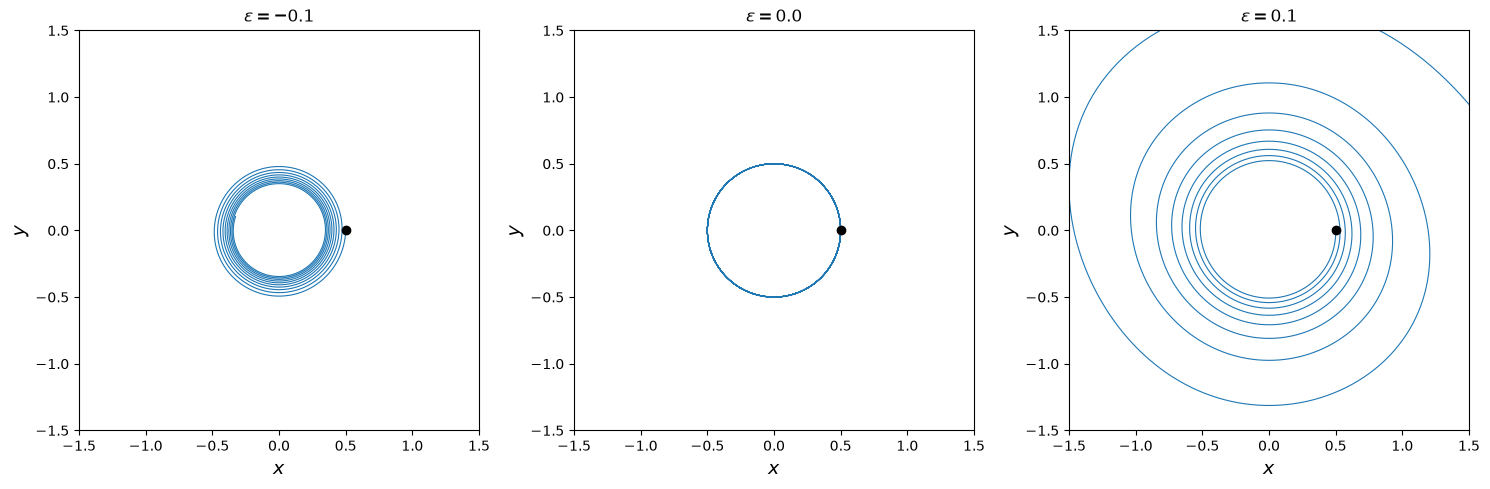

In [ ]:
def rhs_nl(t, y, eps):
    return [y[1] + eps * y[0]**3, -y[0]]

fig = plt.figure(figsize=(15, 5))
for i, e in enumerate([-0.1, 0.0, 0.1]):
    ax = fig.add_subplot(1, 3, i + 1)
    sol = solve_ivp(rhs_nl, (0, 60), [0.5, 0.0], args=(e,), events=izven,
                    rtol=rtol, atol=atol, max_step=0.02)
    ax.plot(sol.y[0], sol.y[1], linewidth=0.8)
    ax.plot(0.5, 0, "o", color="black")
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    ax.set_aspect("equal")
    ax.set_xlabel("$x$", fontsize=14)
    ax.set_ylabel("$y$", fontsize=14)
    ax.set_title(rf"$\epsilon = {e}$")
plt.tight_layout()
plt.show()